In [1]:
#python setup
import pandas as pd
import numpy as np
import statsmodels.api as sm
from sklearn.metrics import roc_auc_score
import seaborn as sns
import matplotlib.pyplot as plt
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [6]:
#import data
data = pd.read_csv("data/Credit Data_v3.csv")

In [7]:
#create the dependent variable
data['Default'] = np.where(data[['Default Date']].isnull(), 0, 1)

In [10]:
#drop non-numeric columns
num_data = data.drop(columns=['Default Date', 'Contract Date'])

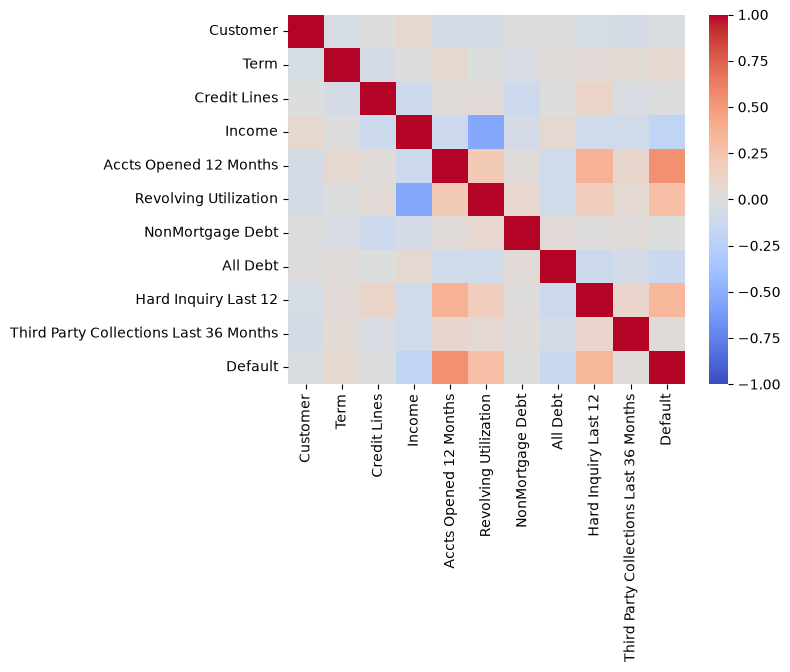

In [16]:
#correlations
correlations = num_data.corr(method = 'pearson')
#heat map
sns.heatmap(correlations, annot=False, cmap='coolwarm', vmin=-1, vmax=1)
#show map
plt.show()

In [20]:
#split data into Y and X
variables = num_data.drop(columns=['Default'])
variables = sm.add_constant(variables)

indep_vars = variables[['Income', 'All Debt', #'Revolving Utilization',
                        'Accts Opened 12 Months', 'Hard Inquiry Last 12']]

In [22]:
#build model
dev_PD = sm.Logit(data['Default'], indep_vars).fit()
print(dev_PD.summary())

Optimization terminated successfully.
         Current function value: 0.219950
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:                Default   No. Observations:                  500
Model:                          Logit   Df Residuals:                      496
Method:                           MLE   Df Model:                            3
Date:                Wed, 21 Oct 2026   Pseudo R-squ.:                  0.3234
Time:                        18:14:48   Log-Likelihood:                -109.98
converged:                       True   LL-Null:                       -162.54
Covariance Type:            nonrobust   LLR p-value:                 1.223e-22
                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
Income                 -3.765e-05   8.27e-06     -4.554      0.000   -5.39e-05   -2.

In [24]:
#predict y values
y_pred_probs = dev_PD.predict(indep_vars)

In [25]:
#AUC
auc_score = roc_auc_score(data['Default'], y_pred_probs)
print(f"AUC Score: {auc_score:.4f}")

AUC Score: 0.8492


In [11]:
print(num_data.head(25))

    Customer  Term  Credit Lines   Income  Accts Opened 12 Months  \
0       4900    60             2  53378.0                       1   
1       5114    60             6  28064.0                       0   
2       6223    72             9  46934.0                       0   
3       9790    48             7  55294.0                       1   
4       7167    72             5  61899.0                       1   
5       3533    84            10  14812.0                       0   
6       7106    24             3  28883.0                       0   
7       1524    48             4  68539.0                       0   
8       8231    84             4  51789.0                       0   
9       2894    60             3  59746.0                       1   
10      3475    72             8  12000.0                       1   
11      1275    72             9  32023.0                       0   
12      4872    36             5  47031.0                       0   
13      6216    24             4  

In [26]:
print(y_pred_probs.head(25))

0     0.912520
1     0.102942
2     0.069790
3     0.714320
4     0.775236
5     0.184261
6     0.204636
7     0.026066
8     0.043709
9     0.829033
10    0.865939
11    0.247024
12    0.092278
13    0.065427
14    0.686559
15    0.059087
16    0.199048
17    0.089771
18    0.600797
19    0.916019
20    0.048432
21    0.049626
22    0.038084
23    0.954790
24    0.039698
dtype: float64
